In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from textblob import TextBlob

df = pd.read_csv("../dataset/cleaned_womens_clothing_reviews.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (23486, 10)


,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,767,33,No Title,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1080,34,No Title,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


In [2]:
review = df['Review Text'][0]

analysis = TextBlob(review)

print("Customer Review:")
print(review)

print("\nSentiment Polarity:", analysis.sentiment.polarity)
print("Sentiment Subjectivity:", analysis.sentiment.subjectivity)

Customer Review:
Absolutely wonderful - silky and sexy and comfortable

Sentiment Polarity: 0.6333333333333333
Sentiment Subjectivity: 0.9333333333333332


In [3]:
df['Polarity'] = df['Review Text'].apply(
    lambda review: TextBlob(str(review)).sentiment.polarity
)

df[['Review Text', 'Polarity']].head(10)

,Review Text,Polarity
0,Absolutely wonderful - silky and sexy and comf...,0.633333
1,Love this dress! it's sooo pretty. i happene...,0.339583
2,I had such high hopes for this dress and reall...,0.073675
3,"I love, love, love this jumpsuit. it's fun, fl...",0.550000
4,This shirt is very flattering to all due to th...,0.512891
5,"I love tracy reese dresses, but this one is no...",0.178750
6,I aded this in my basket at hte last mintue to...,0.133750
7,"I ordered this in carbon for store pick up, an...",0.171635
8,I love this dress. i usually get an xs but it ...,0.002500
9,"I'm 5""5' and 125 lbs. i ordered the s petite t...",0.204200


In [4]:
def get_sentiment(score):
    if score > 0:
        return 'Positive'
    elif score < 0:
        return 'Negative'
    else:
        return 'Neutral'

df['Sentiment'] = df['Polarity'].apply(get_sentiment)

df[['Review Text', 'Polarity', 'Sentiment']].head(10)

,Review Text,Polarity,Sentiment
0,Absolutely wonderful - silky and sexy and comf...,0.633333,Positive
1,Love this dress! it's sooo pretty. i happene...,0.339583,Positive
2,I had such high hopes for this dress and reall...,0.073675,Positive
3,"I love, love, love this jumpsuit. it's fun, fl...",0.550000,Positive
4,This shirt is very flattering to all due to th...,0.512891,Positive
5,"I love tracy reese dresses, but this one is no...",0.178750,Positive
6,I aded this in my basket at hte last mintue to...,0.133750,Positive
7,"I ordered this in carbon for store pick up, an...",0.171635,Positive
8,I love this dress. i usually get an xs but it ...,0.002500,Positive
9,"I'm 5""5' and 125 lbs. i ordered the s petite t...",0.204200,Positive


In [5]:
sentiment_counts = df['Sentiment'].value_counts()

print("Sentiment Analysis Results:")
print("---------------------------")
print(sentiment_counts)

print("\nTotal Reviews:", len(df))

Sentiment Analysis Results:
---------------------------
Sentiment
Positive    21227
Negative     1315
Neutral       944
Name: count, dtype: int64

Total Reviews: 23486


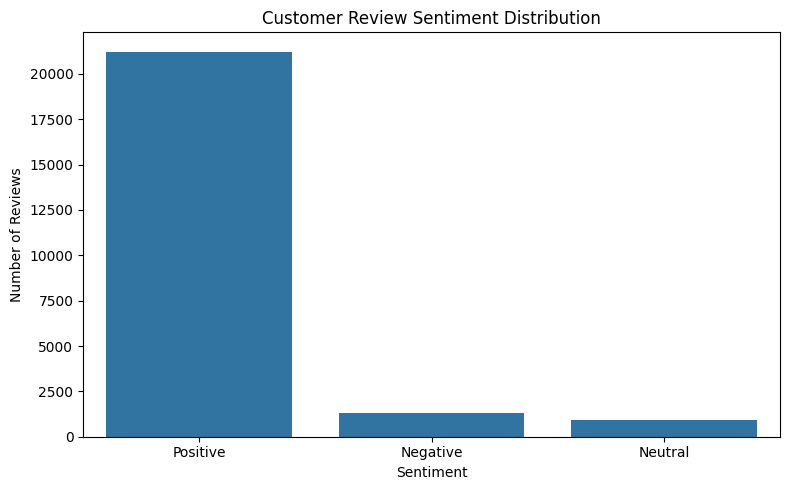

In [6]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Sentiment',
    order=['Positive', 'Negative', 'Neutral']
)

plt.title('Customer Review Sentiment Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')

plt.tight_layout()
plt.savefig('../outputs/sentiment_distribution.png')
plt.show()

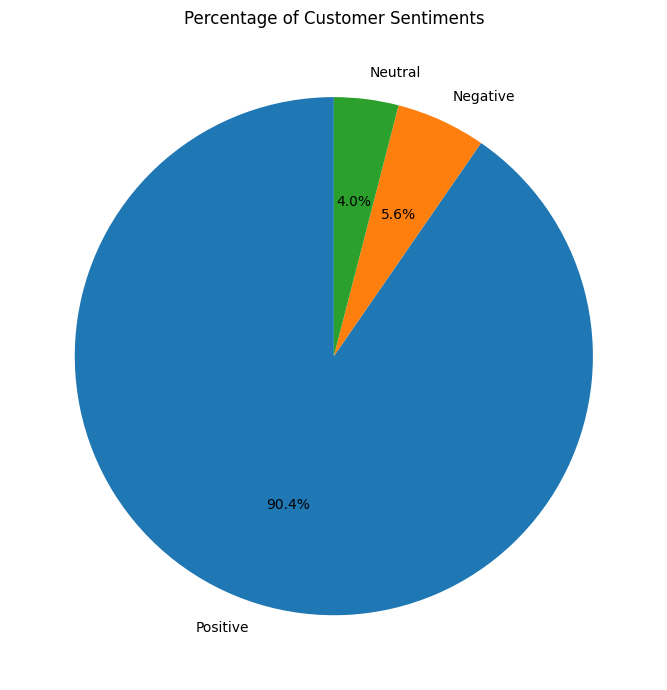

In [7]:
plt.figure(figsize=(7, 7))

sentiment_counts = df['Sentiment'].value_counts()

plt.pie(
    sentiment_counts,
    labels=sentiment_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Percentage of Customer Sentiments')
plt.tight_layout()

plt.savefig('../outputs/sentiment_percentage.png')
plt.show()

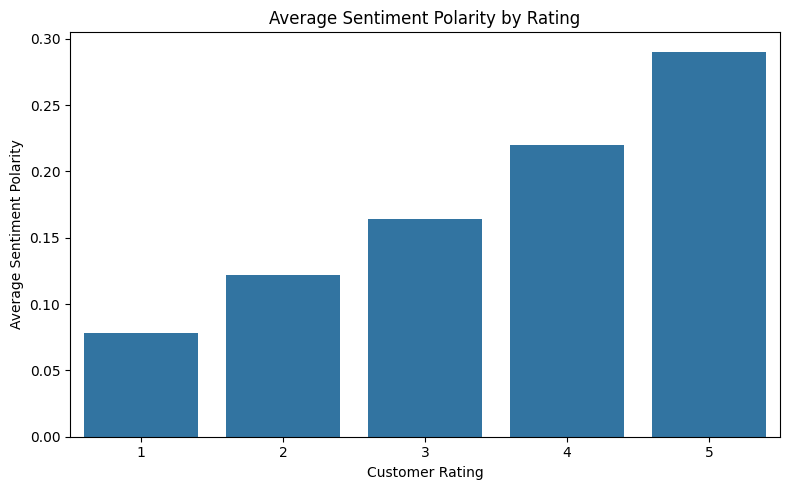

In [8]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='Rating',
    y='Polarity',
    errorbar=None
)

plt.title('Average Sentiment Polarity by Rating')
plt.xlabel('Customer Rating')
plt.ylabel('Average Sentiment Polarity')

plt.tight_layout()
plt.savefig('../outputs/sentiment_by_rating.png')
plt.show()

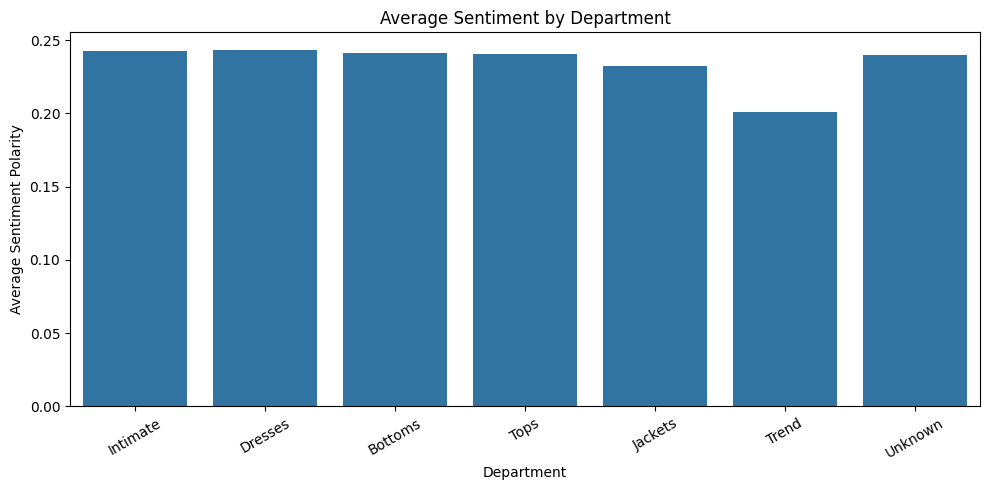

In [9]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x='Department Name',
    y='Polarity',
    errorbar=None
)

plt.title('Average Sentiment by Department')
plt.xlabel('Department')
plt.ylabel('Average Sentiment Polarity')
plt.xticks(rotation=30)

plt.tight_layout()
plt.savefig('../outputs/sentiment_by_department.png')
plt.show()

In [10]:
df.to_csv(
    '../outputs/sentiment_analysis_results.csv',
    index=False
)

print("Sentiment analysis results saved successfully!")
print("Total records:", len(df))

Sentiment analysis results saved successfully!
Total records: 23486


In [11]:
print("FINAL SENTIMENT ANALYSIS REPORT")
print("=" * 40)

print("Total Reviews:", len(df))

print("\nSentiment Counts:")
print(df['Sentiment'].value_counts())

print("\nSentiment Percentages:")
print(
    (df['Sentiment'].value_counts(normalize=True) * 100)
    .round(2)
)

print("\nAverage Polarity:", round(df['Polarity'].mean(), 3))

print("\nMost Common Sentiment:", df['Sentiment'].mode()[0])

FINAL SENTIMENT ANALYSIS REPORT
Total Reviews: 23486

Sentiment Counts:
Sentiment
Positive    21227
Negative     1315
Neutral       944
Name: count, dtype: int64

Sentiment Percentages:
Sentiment
Positive    90.38
Negative     5.60
Neutral      4.02
Name: proportion, dtype: float64

Average Polarity: 0.241

Most Common Sentiment: Positive


## Conclusion

Sentiment analysis was performed on 23,486 customer reviews using Python and TextBlob.

The analysis identified:
- 21,227 Positive reviews (90.38%).
- 1,315 Negative reviews (5.60%).
- 944 Neutral reviews (4.02%).

The average sentiment polarity score was 0.241, indicating an overall positive customer sentiment.

### Final Result
Most customers expressed positive opinions about the clothing products. This analysis helps understand customer satisfaction and identify areas where product quality and customer experience can be improved.

**Tools Used:** Python, Pandas, TextBlob, Matplotlib and Seaborn.